In [12]:
import numpy as np
import torch
import os
import glob
import matplotlib.pyplot as plt

In [23]:
import pandas as pd

# Load the config file into a DataFrame
config_file_path = 'bash_scripts/config/test.csv'
# Load df from csv, type str
df = pd.read_csv(config_file_path, dtype=str)
# Strip leading and trailing spaces from column names
df.columns = df.columns.str.strip()
# Strip leading and trailing spaces from all entries
df = df.map(lambda x: x.strip().replace('\"','\'') if isinstance(x, str) else x)
# Iterate over each row in the DataFrame
for idx, row in df.iterrows():
    ckpt_path = f'ckpt/{row["dataset"]}_{row["usage"]}/{row["model"]}_{row["depth"]}/{row["lr"]}_{row["snr"]}_{row["snvr"]}'
    seeds = row["seed"].split(';')

    # check mean and std of test accuracy already computed
    # accuracy is a string of the form 'mean ± std (n)' and n is the number of seeds
    # if n is same as the number of seeds, then skip this row
    if 'valid_acc' not in row:
        continue

    if '(' in row['valid_acc']:
        n = int(row['valid_acc'].split('(')[-1].split(')')[0])
        if n == len(seeds):
            continue

    valid_accs = []
    test_accs = []
    for seed in seeds:
        seed_path = os.path.join(ckpt_path, seed)
        best_epoch_path = os.path.join(seed_path, 'best_epoch.pth')
        if not os.path.exists(best_epoch_path):
            continue
        best_epoch = torch.load(best_epoch_path)
        valid_accs.append(best_epoch['valid_acc'])
        test_accs.append(best_epoch['test_acc'])        

    if not test_accs:
        df.at[idx, 'valid_acc'] = '-'
        df.at[idx, 'test_acc'] = '-'
    else:
        mean_acc = np.mean(valid_accs)
        std_acc = np.std(valid_accs)
        df.at[idx, 'valid_acc'] = f'{mean_acc:.2f} ± {std_acc:.2f} ({len(valid_accs)})'
        mean_acc = np.mean(test_accs)
        std_acc = np.std(test_accs)
        df.at[idx, 'test_acc'] = f'{mean_acc:.2f} ± {std_acc:.2f} ({len(test_accs)})'
    
df.to_csv(config_file_path, index=False)
df[17:45]

,dataset,usage,model,depth,lr,snr,snvr,seed,valid_acc,test_acc,remark
17,cifar100,1.0,resnet,34x1.5,0.5,0.0,0.0,43,74.01 ± 0.00 (1),73.39 ± 0.00 (1),{}
18,cifar100,1.0,resnet,34x1.5,0.1,0.0,0.0,43;37;13;51;71,76.80 ± 0.88 (5),76.48 ± 0.42 (5),{}
19,cifar100,1.0,resnet,34x1.5,0.05,0.0,0.0,43;37;13;51;71,76.72 ± 0.26 (5),76.57 ± 0.20 (5),{}
20,cifar100,1.0,resnet,34x1.5,0.01,0.0,0.0,43,72.56 ± 0.00 (1),72.35 ± 0.00 (1),{}
21,cifar100,1.0,resnet,34x1.5,0.1,0.1,0.0,43,76.47 ± 0.00 (1),75.79 ± 0.00 (1),{}
22,cifar100,1.0,resnet,34x1.5,0.1,0.01,0.0,43;37;13;51;71,78.25 ± 0.43 (5),77.92 ± 0.18 (5),{}
23,cifar100,1.0,resnet,34x1.5,0.1,0.001,0.0,43,77.98 ± 0.00 (1),76.73 ± 0.00 (1),{}
24,cifar100,1.0,resnet,34x1.5,0.1,0.0001,0.0,43,77.58 ± 0.00 (1),76.61 ± 0.00 (1),{}
25,cifar100,1.0,resnet,34x1.5,0.1,0.01,1.0,43;37;13;51;71,78.63 ± 0.32 (5),78.28 ± 0.14 (5),{}
26,cifar100,1.0,resnet,34x1.5,0.1,0.01,0.1,43;37;13;51;71,78.55 ± 0.36 (5),78.35 ± 0.25 (5),{}


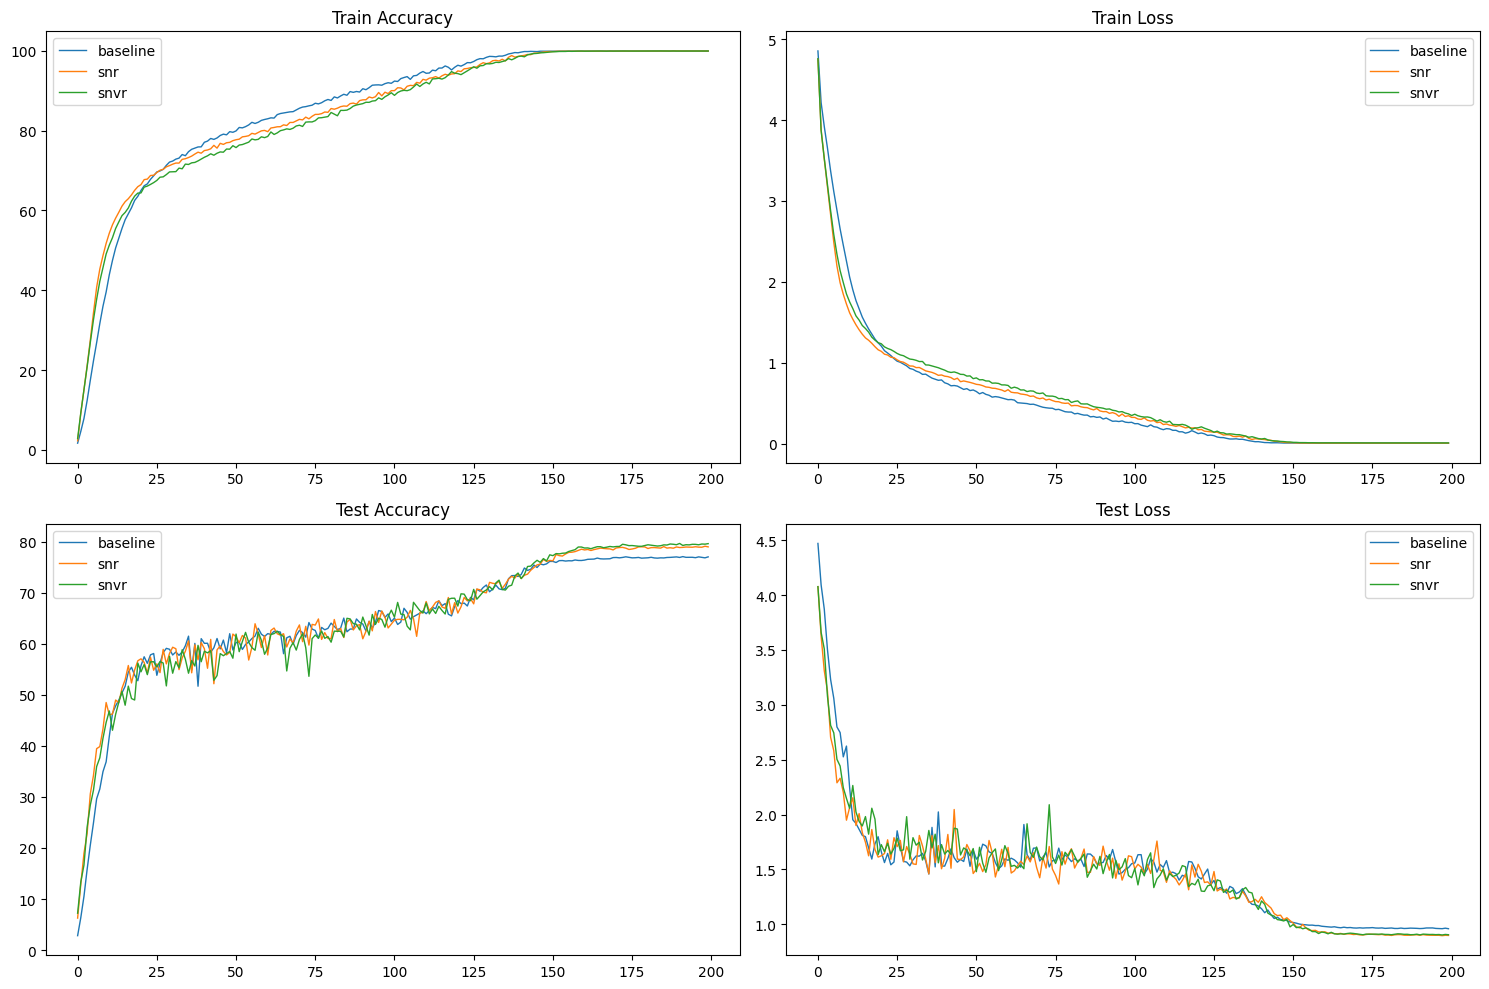

In [22]:
seed = 43

ckpt_paths = [
    f'ckpt/cifar100_1.0/resnet_50/0.05_0.0_0.0/{seed}/training_stats.pth',
    f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.0/{seed}/training_stats.pth',
    f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.1/{seed}/training_stats.pth',
]

labels = ['baseline', 'snr', 'snvr']

stats = []
for ckpt_path in ckpt_paths:
    ckpt = torch.load(ckpt_path)
    stats.append(ckpt)

fig, ax = plt.subplots(2, 2, figsize=(15, 10))

for i, stat in enumerate(stats):
    ax[0, 0].plot(stat['train_acc'], label=f'{labels[i]}', linewidth=1)
    ax[0, 1].plot(stat['train_loss'], label=f'{labels[i]}', linewidth=1)
    ax[1, 0].plot(stat['test_acc'], label=f'{labels[i]}', linewidth=1)
    ax[1, 1].plot(stat['test_loss'], label=f'{labels[i]}', linewidth=1)

ax[0, 0].set_title('Train Accuracy')
ax[0, 1].set_title('Train Loss')
ax[1, 0].set_title('Test Accuracy')
ax[1, 1].set_title('Test Loss')

for axes in ax.flat:
    axes.legend()

plt.tight_layout()
plt.show()

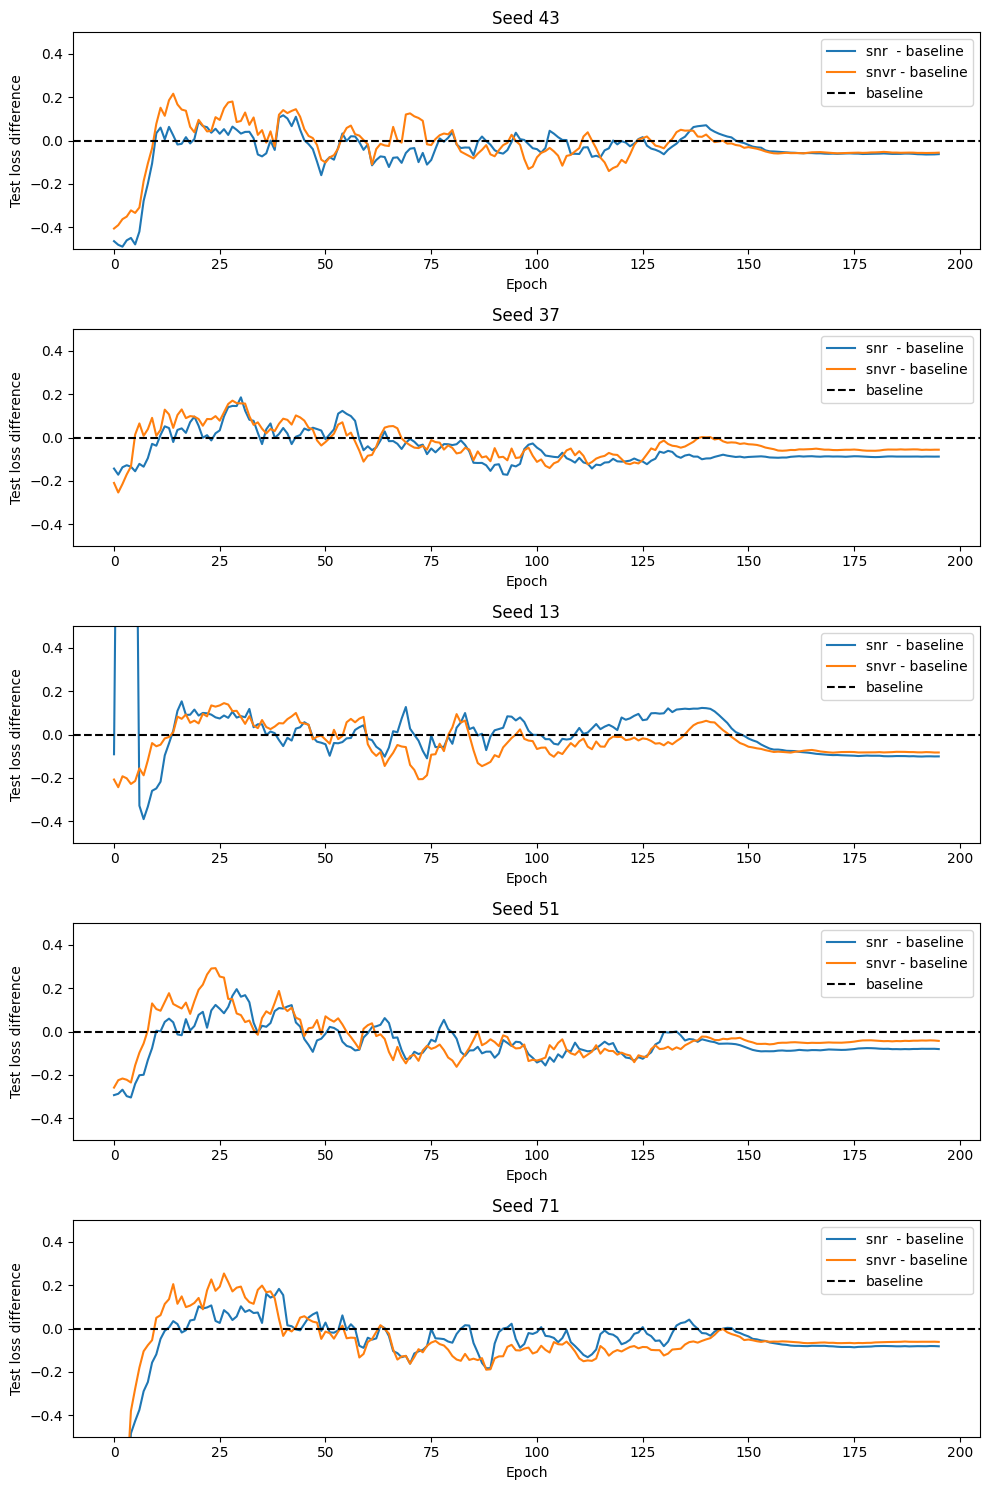

In [15]:
seeds = ['43','37','13','51','71']

# subplots for each
fig, axs = plt.subplots(5, 1, figsize=(10, 15))

for i, seed in enumerate(seeds):
    # learning curves
    ckpt_paths = [
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.0_0.0/{seed}/training_stats.pth',
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.0/{seed}/training_stats.pth',
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.1/{seed}/training_stats.pth',
    ]

    stats = []
    for ckpt_path in ckpt_paths:
        ckpt = torch.load(ckpt_path)
        stats.append(ckpt['test_loss'])

    window_size = 5
    stats_moving_avg = [np.convolve(stat, np.ones(window_size)/window_size, mode='valid') for stat in stats]
    axs[i].plot(np.array(stats_moving_avg[1]) - np.array(stats_moving_avg[0]), label=f'snr  - baseline')
    axs[i].plot(np.array(stats_moving_avg[2]) - np.array(stats_moving_avg[0]), label=f'snvr - baseline')
    axs[i].set_title(f'Seed {seed}')
    axs[i].axhline(0, color='black', linestyle='--', label='baseline')
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Test loss difference')
    axs[i].set_ylim(-0.5, 0.5)
    axs[i].legend()

plt.tight_layout()
plt.show()

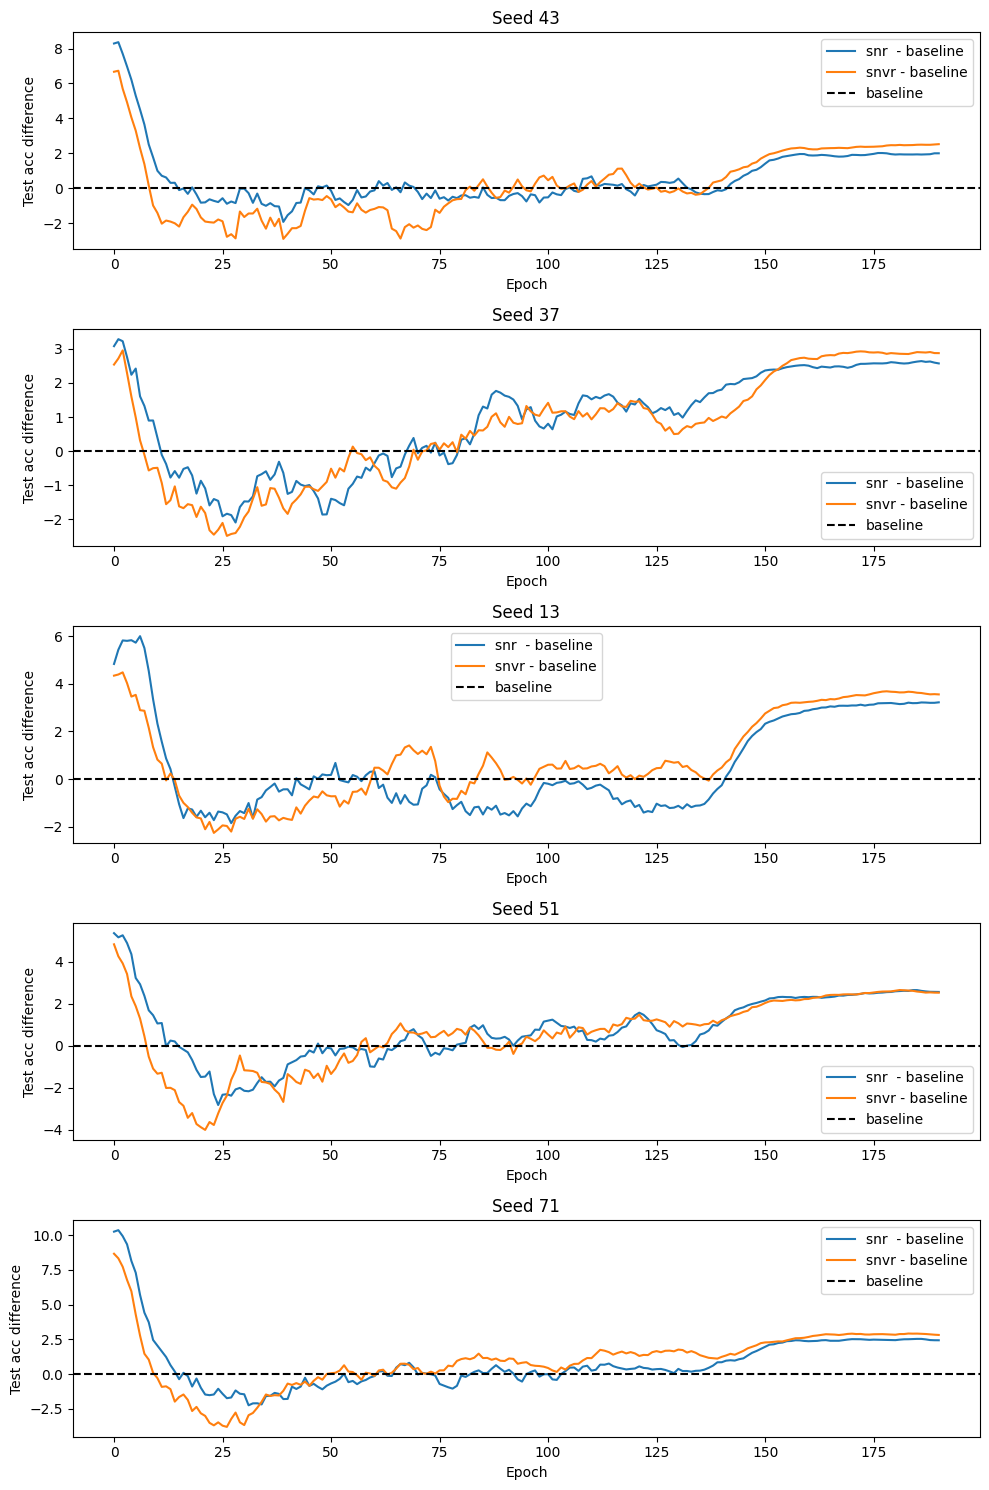

In [16]:
seeds = ['43','37','13','51','71']

# subplots for each
fig, axs = plt.subplots(5, 1, figsize=(10, 15))

for i, seed in enumerate(seeds):
    # learning curves
    ckpt_paths = [
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.0_0.0/{seed}/training_stats.pth',
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.0/{seed}/training_stats.pth',
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.1/{seed}/training_stats.pth',
    ]

    stats = []
    for ckpt_path in ckpt_paths:
        ckpt = torch.load(ckpt_path)
        stats.append(ckpt['test_acc'])

    window_size = 10
    stats_moving_avg = [np.convolve(stat, np.ones(window_size)/window_size, mode='valid') for stat in stats]
    axs[i].plot(np.array(stats_moving_avg[1]) - np.array(stats_moving_avg[0]), label=f'snr  - baseline')
    axs[i].plot(np.array(stats_moving_avg[2]) - np.array(stats_moving_avg[0]), label=f'snvr - baseline')
    axs[i].set_title(f'Seed {seed}')
    axs[i].axhline(0, color='black', linestyle='--', label='baseline')
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Test acc difference')
    # axs[i].set_ylim(-0.5, 0.5)
    axs[i].legend()

plt.tight_layout()
plt.show()

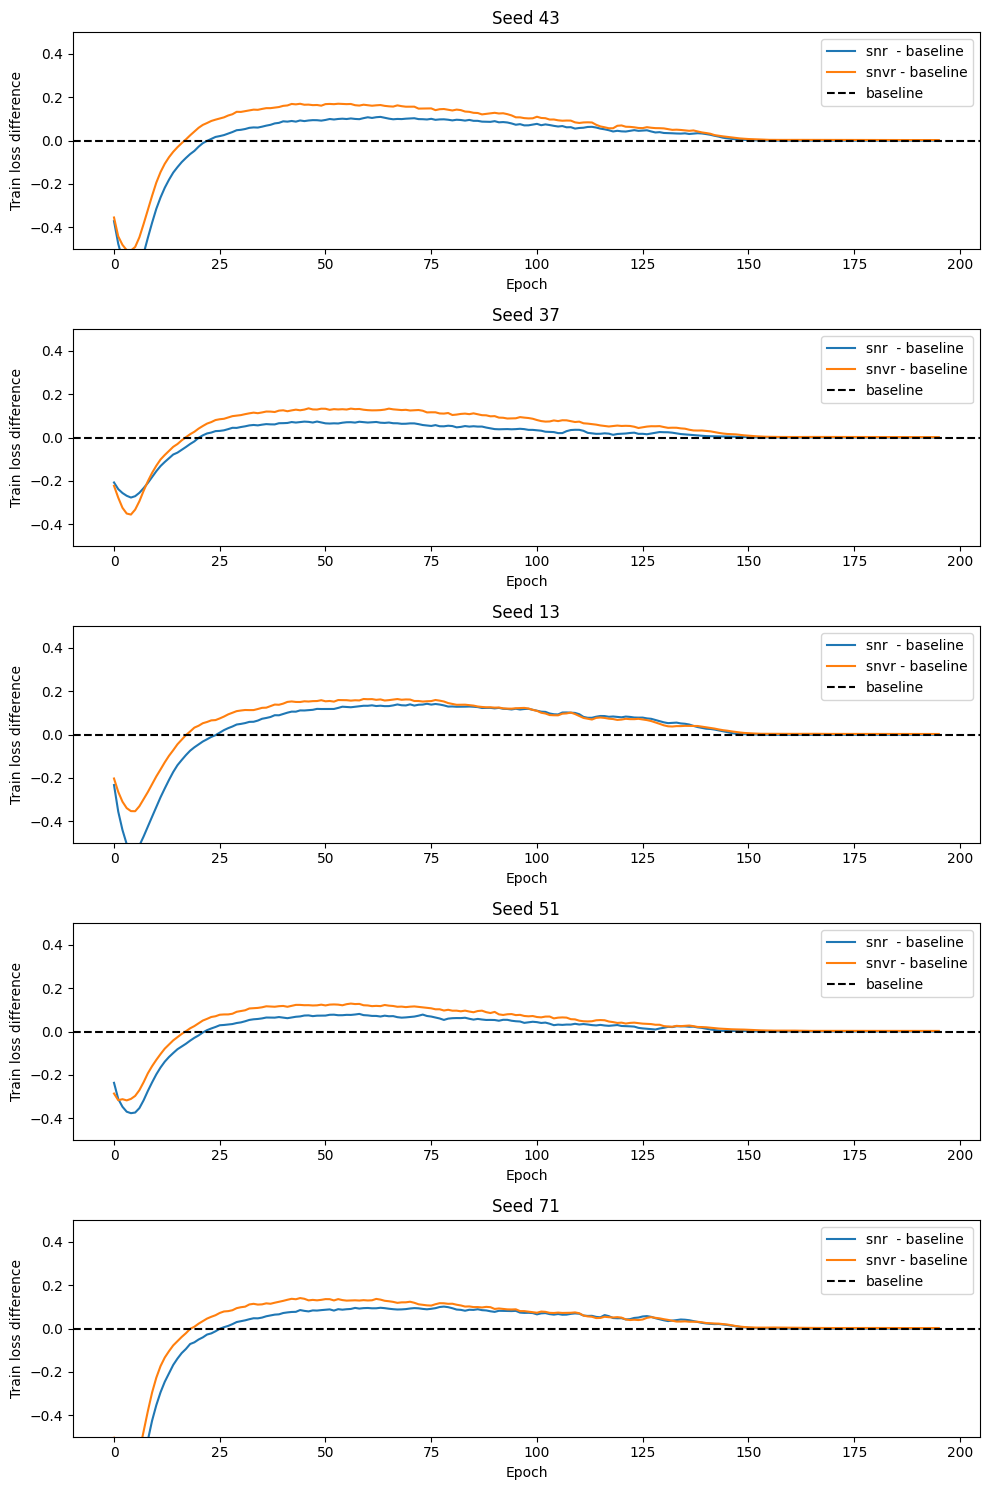

In [17]:
seeds = ['43','37','13','51','71']

# subplots for each
fig, axs = plt.subplots(5, 1, figsize=(10, 15))

for i, seed in enumerate(seeds):
    # learning curves
    ckpt_paths = [
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.0_0.0/{seed}/training_stats.pth',
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.0/{seed}/training_stats.pth',
        f'ckpt/cifar100_1.0/resnet_50/0.05_0.01_0.1/{seed}/training_stats.pth',
    ]

    stats = []
    for ckpt_path in ckpt_paths:
        ckpt = torch.load(ckpt_path)
        stats.append(ckpt['train_loss'])

    window_size = 5
    stats_moving_avg = [np.convolve(stat, np.ones(window_size)/window_size, mode='valid') for stat in stats]
    axs[i].plot(np.array(stats_moving_avg[1]) - np.array(stats_moving_avg[0]), label=f'snr  - baseline')
    axs[i].plot(np.array(stats_moving_avg[2]) - np.array(stats_moving_avg[0]), label=f'snvr - baseline')
    axs[i].set_title(f'Seed {seed}')
    axs[i].axhline(0, color='black', linestyle='--', label='baseline')
    axs[i].set_xlabel('Epoch')
    axs[i].set_ylabel('Train loss difference')
    axs[i].set_ylim(-0.5, 0.5)
    axs[i].legend()

plt.tight_layout()
plt.show()